# 05 - Evaluation (per-class metrics, confusion matrix, realistic probes)

**Goal:** evaluate the best fine-tuned model from notebook 04 with:
- overall accuracy/loss on val and test splits
- per-class precision/recall/F1
- confusion matrix
- optional field-photo and unsupported-folder probes


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
import torch_directml

In [3]:


NOTEBOOK_ROOT = Path.cwd()
PROJECT_ROOT = NOTEBOOK_ROOT.parent
ARTIFACTS = PROJECT_ROOT / "agrilens-training/artifacts"
ARTIFACTS.mkdir(exist_ok=True)

dml = torch_directml.device()
print("DirectML device:", torch_directml.device_name(0))


DirectML device: AMD Radeon RX 5700 


### Step 1 - load artifacts and model checkpoint

In [4]:
class_map_path = ARTIFACTS / "class_map.json"
manifest_path = ARTIFACTS / "manifest_v2.csv"
preprocess_path = ARTIFACTS / "preprocess_contract.json"
fine_tune_report_path = ARTIFACTS / "fine_tune_report.json"

for p in [class_map_path, manifest_path, preprocess_path, fine_tune_report_path]:
    if not p.exists():
        raise FileNotFoundError(f"Missing artifact: {p}")

class_map = json.loads(class_map_path.read_text(encoding="utf-8"))
labels = [c["label"] for c in sorted(class_map, key=lambda x: x["id"])]
num_classes = len(labels)

manifest = pd.read_csv(manifest_path)
manifest["class_id"] = manifest["class_id"].astype(int)
manifest["split"] = manifest["split"].astype(str).str.lower()

preprocess = json.loads(preprocess_path.read_text(encoding="utf-8"))
input_size = int(preprocess["input_size"])
mean = preprocess["mean"]
std = preprocess["std"]

fine_tune_report = json.loads(fine_tune_report_path.read_text(encoding="utf-8"))
checkpoint_path = Path(fine_tune_report["best_run"]["checkpoint"])
if not checkpoint_path.exists():
    raise FileNotFoundError(f"Missing checkpoint from fine_tune_report: {checkpoint_path}")

print("checkpoint:", checkpoint_path)
print("best run:", fine_tune_report["best_run"])
print(manifest.groupby(["split", "class_id"]).size().unstack(fill_value=0))


checkpoint: C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\mobilenetv3_finetune_best.pt
best run: {'seed': 123, 'best_epoch': 12, 'best_val_loss': 0.025906379482849188, 'val_acc': 0.9906759906759907, 'test_loss': 0.02911509823457751, 'test_acc': 0.9912485414235706, 'checkpoint': 'C:\\Users\\baabyface\\Documents\\my work\\agrilens\\agrilens-training\\artifacts\\mobilenetv3_finetune_best.pt'}
class_id    0    1    2    3     4    5     6    7     8
split                                                   
test      179  148   77  174   319  150   286  143   238
train     834  689  359  814  1489  700  1336  666  1114
val       179  148   77  174   319  150   287  143   239


### Step 2 - datasets and inference helpers

In [5]:
eval_tfms = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class EvalDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, tfm):
        self.frame = frame.reset_index(drop=True)
        self.tfm = tfm

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row.path).convert("RGB")
        x = self.tfm(img)
        y = int(row.class_id)
        return x, y, row.path

def make_loader(frame: pd.DataFrame, batch_size=64):
    ds = EvalDataset(frame, eval_tfms)
    return DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)

loss_fn = nn.CrossEntropyLoss()

def build_model(checkpoint: Path):
    model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    obj = torch.load(checkpoint, map_location="cpu")
    state = obj["state_dict"] if isinstance(obj, dict) and "state_dict" in obj else obj
    model.load_state_dict(state)
    model = model.to(dml).eval()
    return model

@torch.no_grad()
def run_eval(model, loader):
    all_y = []
    all_pred = []
    all_prob = []
    all_paths = []
    loss_sum = 0.0
    n = 0

    for xb, yb, paths in loader:
        xb = xb.to(dml)
        yb = yb.to(dml)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        prob = torch.softmax(logits, dim=1)

        bs = yb.shape[0]
        loss_sum += float(loss.item()) * bs
        n += bs

        all_y.append(yb.cpu().numpy())
        all_pred.append(prob.argmax(1).cpu().numpy())
        all_prob.append(prob.cpu().numpy())
        all_paths.extend(list(paths))

    y = np.concatenate(all_y)
    pred = np.concatenate(all_pred)
    prob = np.concatenate(all_prob)
    return {
        "loss": loss_sum / max(n, 1),
        "acc": float((pred == y).mean()),
        "y": y,
        "pred": pred,
        "prob": prob,
        "paths": all_paths,
    }

def confusion_matrix_np(y_true, y_pred, k):
    idx = y_true * k + y_pred
    cm = np.bincount(idx, minlength=k * k).reshape(k, k)
    return cm

def per_class_metrics(cm, labels):
    rows = []
    for i, label in enumerate(labels):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        support = cm[i, :].sum()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        rows.append(
            {
                "class_id": i,
                "label": label,
                "support": int(support),
                "precision": float(precision),
                "recall": float(recall),
                "f1": float(f1),
            }
        )
    return pd.DataFrame(rows)


### Step 3 - evaluate on validation and test splits

In [6]:
model = build_model(checkpoint_path)

val_df = manifest[manifest.split == "val"].copy()
test_df = manifest[manifest.split == "test"].copy()

val_out = run_eval(model, make_loader(val_df))
test_out = run_eval(model, make_loader(test_df))

print("val :", {"loss": round(val_out["loss"], 4), "acc": round(val_out["acc"], 4)})
print("test:", {"loss": round(test_out["loss"], 4), "acc": round(test_out["acc"], 4)})


C:\Users\baabyface\AppData\Local\Temp\ipykernel_4860\582544981.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  obj = torch.load(checkpoint, map_location="cpu")


val : {'loss': 0.0257, 'acc': 0.9907}
test: {'loss': 0.0271, 'acc': 0.9912}


In [7]:
val_cm = confusion_matrix_np(val_out["y"], val_out["pred"], num_classes)
test_cm = confusion_matrix_np(test_out["y"], test_out["pred"], num_classes)

val_cls = per_class_metrics(val_cm, labels).assign(split="val")
test_cls = per_class_metrics(test_cm, labels).assign(split="test")
cls_metrics = pd.concat([val_cls, test_cls], ignore_index=True)

macro_f1_val = float(val_cls["f1"].mean())
macro_f1_test = float(test_cls["f1"].mean())
print("macro F1 val :", round(macro_f1_val, 4))
print("macro F1 test:", round(macro_f1_test, 4))

display_cols = ["split", "class_id", "label", "support", "precision", "recall", "f1"]
cls_metrics[display_cols].sort_values(["split", "class_id"]).reset_index(drop=True)


macro F1 val : 0.9843
macro F1 test: 0.9868


,split,class_id,label,support,precision,recall,f1
0,test,0,maize__common_rust,179,0.994444,1.000000,0.997214
1,test,1,maize__northern_leaf_blight,148,0.960265,0.979730,0.969900
2,test,2,maize__gray_leaf_spot,77,0.972603,0.922078,0.946667
3,test,3,maize__healthy,174,1.000000,1.000000,1.000000
4,test,4,tomato__bacterial_spot,319,0.996875,1.000000,0.998435
5,test,5,tomato__early_blight,150,1.000000,0.960000,0.979592
6,test,6,tomato__late_blight,286,0.986207,1.000000,0.993056
7,test,7,tomato__leaf_mold,143,0.993056,1.000000,0.996516
8,test,8,tomato__healthy,238,1.000000,1.000000,1.000000
9,val,0,maize__common_rust,179,1.000000,1.000000,1.000000


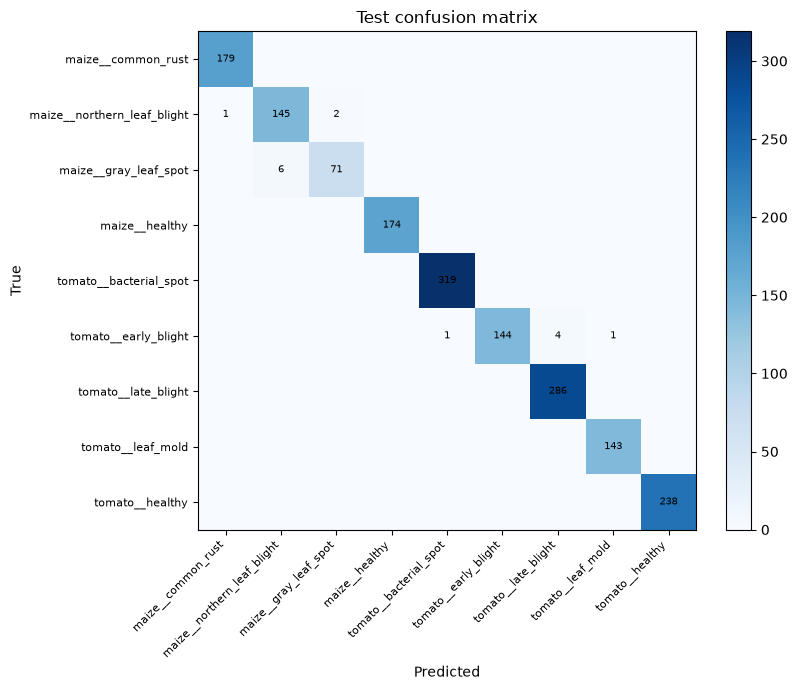

In [8]:
def plot_cm(cm, labels, title):
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = int(cm[i, j])
            if v > 0:
                ax.text(j, i, str(v), ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

plot_cm(test_cm, labels, "Test confusion matrix")


In [9]:
metrics_csv = ARTIFACTS / "evaluation_per_class_metrics.csv"
cls_metrics.to_csv(metrics_csv, index=False)

np.save(ARTIFACTS / "evaluation_test_confusion_matrix.npy", test_cm)

summary = {
    "checkpoint": str(checkpoint_path),
    "val": {
        "loss": float(val_out["loss"]),
        "acc": float(val_out["acc"]),
        "macro_f1": macro_f1_val
    },
    "test": {
        "loss": float(test_out["loss"]),
        "acc": float(test_out["acc"]),
        "macro_f1": macro_f1_test
    }
}
(ARTIFACTS / "evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved", metrics_csv)
print("saved", ARTIFACTS / "evaluation_test_confusion_matrix.npy")
print("saved", ARTIFACTS / "evaluation_summary.json")
print(json.dumps(summary, indent=2))


saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\evaluation_per_class_metrics.csv
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\evaluation_test_confusion_matrix.npy
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\evaluation_summary.json
{
  "checkpoint": "C:\\Users\\baabyface\\Documents\\my work\\agrilens\\agrilens-training\\artifacts\\mobilenetv3_finetune_best.pt",
  "val": {
    "loss": 0.025662686206445306,
    "acc": 0.9906759906759907,
    "macro_f1": 0.9842969158278814
  },
  "test": {
    "loss": 0.027087300906816398,
    "acc": 0.9912485414235706,
    "macro_f1": 0.9868198826004458
  }
}


### Step 4 - optional realistic probes

1) Field photos folder (`data/field_photos`) if present.
2) Unsupported PlantVillage folders listed by notebook 01.

In [10]:
IMG_EXT = {".jpg", ".jpeg", ".png"}

def list_images_recursive(root: Path):
    if not root.exists():
        return []
    return sorted([p for p in root.rglob("*") if p.suffix.lower() in IMG_EXT])

@torch.no_grad()
def infer_unlabeled(model, paths, batch_size=64):
    class UnlabeledDS(Dataset):
        def __init__(self, paths):
            self.paths = paths
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, idx):
            p = self.paths[idx]
            x = eval_tfms(Image.open(p).convert("RGB"))
            return x, str(p)

    if len(paths) == 0:
        return pd.DataFrame(columns=["path", "pred_class_id", "pred_label", "max_prob"])

    loader = DataLoader(UnlabeledDS(paths), batch_size=batch_size, shuffle=False, num_workers=0)
    rows = []
    for xb, pth in loader:
        xb = xb.to(dml)
        prob = torch.softmax(model(xb), dim=1).cpu().numpy()
        pred = prob.argmax(axis=1)
        mx = prob.max(axis=1)
        for i in range(len(pred)):
            rows.append({
                "path": pth[i],
                "pred_class_id": int(pred[i]),
                "pred_label": labels[int(pred[i])],
                "max_prob": float(mx[i]),
            })
    return pd.DataFrame(rows)

probe_summary = {}

field_root = NOTEBOOK_ROOT / "data" / "field_photos"
field_paths = list_images_recursive(field_root)
print("field photos found:", len(field_paths), "at", field_root)
field_pred = infer_unlabeled(model, field_paths)
if len(field_pred) > 0:
    field_pred.to_csv(ARTIFACTS / "field_photos_predictions.csv", index=False)
    probe_summary["field_photos"] = {
        "n": int(len(field_pred)),
        "max_prob_median": float(field_pred["max_prob"].median()),
        "max_prob_p10": float(field_pred["max_prob"].quantile(0.10)),
        "max_prob_p90": float(field_pred["max_prob"].quantile(0.90)),
        "top_pred_counts": field_pred["pred_label"].value_counts().head(6).to_dict(),
    }
    print("saved", ARTIFACTS / "field_photos_predictions.csv")
else:
    probe_summary["field_photos"] = {"n": 0, "note": "folder missing or empty"}

unsupported_json = ARTIFACTS / "unsupported_folders.json"
if unsupported_json.exists():
    unsupported_map = json.loads(unsupported_json.read_text(encoding="utf-8"))
    raw_root = NOTEBOOK_ROOT / "data" / "plantvillage" / "raw" / "color"
    all_unsupported = []
    for folder in unsupported_map.keys():
        all_unsupported.extend(list_images_recursive(raw_root / folder))
    print("unsupported images found:", len(all_unsupported))

    unsupported_pred = infer_unlabeled(model, all_unsupported)
    if len(unsupported_pred) > 0:
        unsupported_pred.to_csv(ARTIFACTS / "unsupported_predictions.csv", index=False)
        probe_summary["unsupported"] = {
            "n": int(len(unsupported_pred)),
            "max_prob_median": float(unsupported_pred["max_prob"].median()),
            "max_prob_p10": float(unsupported_pred["max_prob"].quantile(0.10)),
            "max_prob_p90": float(unsupported_pred["max_prob"].quantile(0.90)),
            "top_pred_counts": unsupported_pred["pred_label"].value_counts().head(6).to_dict(),
        }
        print("saved", ARTIFACTS / "unsupported_predictions.csv")
    else:
        probe_summary["unsupported"] = {"n": 0, "note": "no unsupported images found"}
else:
    probe_summary["unsupported"] = {"n": 0, "note": "unsupported_folders.json missing"}

(ARTIFACTS / "evaluation_probe_summary.json").write_text(json.dumps(probe_summary, indent=2), encoding="utf-8")
print("saved", ARTIFACTS / "evaluation_probe_summary.json")
print(json.dumps(probe_summary, indent=2))


field photos found: 15 at C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\data\field_photos
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\field_photos_predictions.csv
unsupported images found: 0
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\evaluation_probe_summary.json
{
  "field_photos": {
    "n": 15,
    "max_prob_median": 0.8603691458702087,
    "max_prob_p10": 0.5683518409729004,
    "max_prob_p90": 0.999809718132019,
    "top_pred_counts": {
      "tomato__late_blight": 9,
      "maize__gray_leaf_spot": 3,
      "maize__healthy": 1,
      "tomato__early_blight": 1,
      "tomato__leaf_mold": 1
    }
  },
  "unsupported": {
    "n": 0,
    "note": "no unsupported images found"
  }
}
